,gemeente,laadpunten_regulier_publiek,huishoudens,gem_gestandaardiseerd_inkomen_keur,med_gestandaardiseerd_inkomen_keur,gem_besteedbaar_inkomen_keur,med_besteedbaar_inkomen_keur,laadpunten_per_1000_huishoudens
0,'s-Hertogenbosch,1817,75500,44.3,38.0,62.9,49.0,24.07
1,Aa en Hunze,89,11400,42.6,38.9,62.5,54.0,7.81
2,Aalsmeer,316,14200,52.1,40.0,77.4,56.2,22.25
3,Aalten,138,11700,40.5,36.4,60.3,50.4,11.79
4,Achtkarspelen,54,12000,36.3,33.7,54.0,46.3,4.50


,gemeente,laadpunten_per_1000_huishoudens
0,'s-Hertogenbosch,24.07
1,Aa en Hunze,7.81
2,Aalsmeer,22.25
3,Aalten,11.79
4,Achtkarspelen,4.50


,id,code,identificatie,ligt_in_provincie_code,ligt_in_provincie_naam,naam,geometry
0,d29f1e45-ae7b-5bfd-9f98-3aabeffb7454,0263,GM0263,25,Gelderland,Maasdriel,"MULTIPOLYGON (((5.26613 51.7393, 5.26704 51.73..."
1,5e0d55b1-8212-5c3a-b8b4-72bde82fb1fb,0441,GM0441,27,Noord-Holland,Schagen,"MULTIPOLYGON (((4.71723 52.70422, 4.7174 52.70..."
2,dc868e6c-021a-532e-8e26-512e2803ae8e,1903,GM1903,31,Limburg,Eijsden-Margraten,"MULTIPOLYGON (((5.69601 50.75503, 5.69661 50.7..."
3,b3116687-94e0-57ab-9753-3ae63b716c11,0193,GM0193,23,Overijssel,Zwolle,"MULTIPOLYGON (((6.10191 52.46469, 6.10193 52.4..."
4,5aad0072-5dfd-50af-8a25-f7d554a81312,1711,GM1711,31,Limburg,Echt-Susteren,"MULTIPOLYGON (((5.85719 51.02854, 5.85921 51.0..."


Kolommen:
Index(['id', 'code', 'identificatie', 'ligt_in_provincie_code',
       'ligt_in_provincie_naam', 'naam', 'geometry'],
      dtype='str')

Aantal gemeenten in de kaart:
342
Aantal gemeenten met laadpuntendata: 338
Aantal gemeenten zonder laadpuntendata: 4


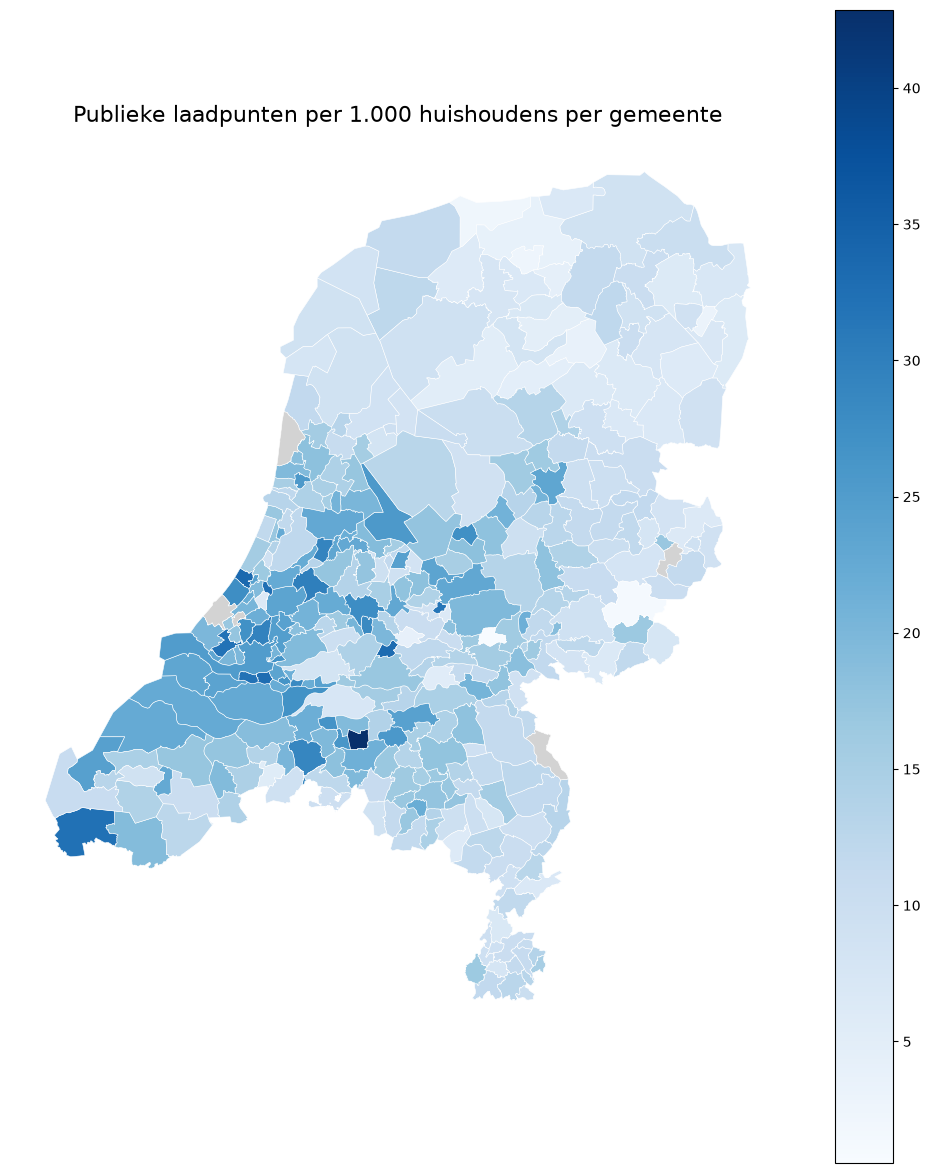

In [5]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt


# ============================================================
# 1. LAADPUNTENDATA INLEZEN
# ============================================================

df = pd.read_csv(
    "/Users/mirtebatema/Desktop/TIL_2026/programming/opdracht/laadpunten_inkomen_per_gemeente.csv",
    sep=None,
    engine="python"
)

# Even controleren
display(df.head())


# ============================================================
# 2. ALLEEN DE KOLOMMEN SELECTEREN DIE WE NODIG HEBBEN
# ============================================================

data = df[
    ["gemeente", "laadpunten_per_1000_huishoudens"]
].copy()

# Rijen zonder waarde verwijderen
data = data.dropna(
    subset=["gemeente", "laadpunten_per_1000_huishoudens"]
)

display(data.head())


# ============================================================
# 3. GEMEENTEGRENZEN VAN NEDERLAND OPHALEN VIA PDOK
# ============================================================

url = (
    "https://api.pdok.nl/kadaster/brk-bestuurlijke-gebieden/"
    "ogc/v1/collections/gemeentegebied/items?f=json&limit=500"
)

gemeenten = gpd.read_file(url)

# Controleren
display(gemeenten.head())

print("Kolommen:")
print(gemeenten.columns)

print("\nAantal gemeenten in de kaart:")
print(len(gemeenten))


# ============================================================
# 4. GEMEENTENAMEN OPSCHONEN
# ============================================================

# Spaties voor/achter namen verwijderen
data["gemeente"] = data["gemeente"].str.strip()
gemeenten["naam"] = gemeenten["naam"].str.strip()


# ============================================================
# 5. LAADPUNTENDATA KOPPELEN AAN DE GEMEENTEKAART
# ============================================================

kaart = gemeenten.merge(
    data,
    left_on="naam",
    right_on="gemeente",
    how="left"
)


# ============================================================
# 6. CONTROLEREN OF DE KOPPELING GOED IS GEGAAN
# ============================================================

print(
    "Aantal gemeenten met laadpuntendata:",
    kaart["laadpunten_per_1000_huishoudens"].notna().sum()
)

print(
    "Aantal gemeenten zonder laadpuntendata:",
    kaart["laadpunten_per_1000_huishoudens"].isna().sum()
)


# ============================================================
# 7. KAART VAN NEDERLAND MAKEN
# ============================================================

fig, ax = plt.subplots(figsize=(10, 12))

kaart.plot(
    column="laadpunten_per_1000_huishoudens",
    cmap="Blues",
    linewidth=0.4,
    edgecolor="white",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "white",
        "label": "Geen data"
    }
)

ax.set_title(
    "Publieke laadpunten per 1.000 huishoudens per gemeente",
    fontsize=16
)

ax.axis("off")

plt.tight_layout()
plt.show()